# Task 2-1 ECG Recognition

In [1]:
%matplotlib widget

In [2]:
# necessary packages
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [3]:
sns.set_theme()

## Load data from `ECG.txt`

Data specification:
- 250 Hz, 10 seconds
- First line, a comment with a leading `#`
- Following lines, each contains a single float value, representing the ECG signal value at a given time point.

In [4]:
FILE_PATH = 'ECG.txt'
SAMPLE_RATE = 250 # Hz

ecg_data = []

with open(FILE_PATH, 'r') as file:
    for line in file:
        if not line.startswith('#'):
            ecg_data.append(float(line.strip()))

ecg_data = np.array(ecg_data)
time_axis = np.arange(len(ecg_data)) / SAMPLE_RATE

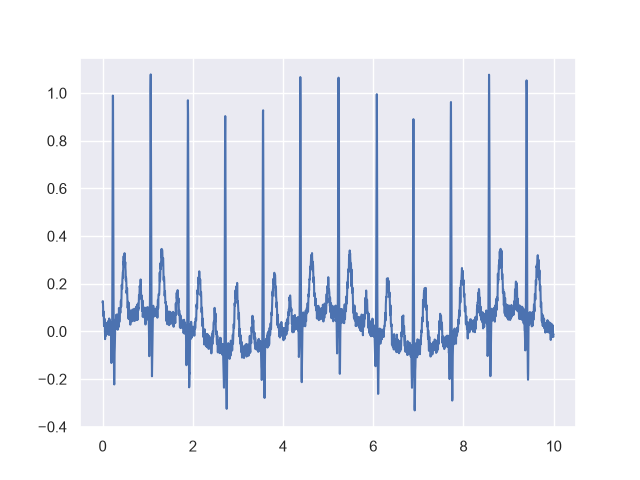

In [5]:
# plot the ECG data with seaborn default settings, using a line plot
# map the x-axis to the actual time and the y-axis to the ECG data values
plt.figure()
sns.lineplot(x=time_axis, y=ecg_data)
plt.show()

## Identifying the R peaks

### Using `scipy.signal.find_peaks` to identify the R peaks in the ECG signal

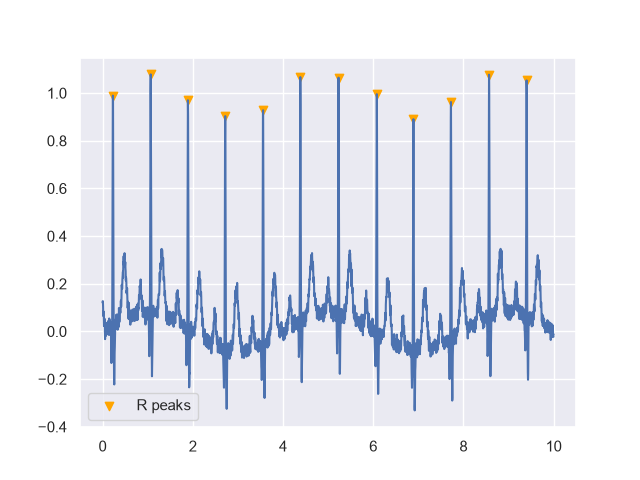

In [6]:
import scipy.signal as signal

MAX_HEART_RATE = 90 * 1.05  # bpm
# minimum distance between peaks in samples
MIN_PEAK_DISTANCE = SAMPLE_RATE * 60 / MAX_HEART_RATE

# Find the R peaks in the ECG data
# 0.6 seconds minimum distance between peaks, meaning a maximum heart rate of 100 bpm
r_peaks = signal.find_peaks(
    ecg_data, height=0.5, distance=MIN_PEAK_DISTANCE)[0]

# Plot the ECG data with the R peaks marked
plt.figure()
sns.lineplot(x=time_axis, y=ecg_data)
plt.scatter(
    time_axis[r_peaks],
    ecg_data[r_peaks],
    label='R peaks', color='orange', marker='v')
plt.legend()
plt.show()

### Alternative: using bool indexing and statistics to identify the R peaks in the ECG signal

In [7]:
def percentile_find_peaks(
    data,
    percentile=99.0,
    distance=None,
):
    """
    Find peaks by percentile thresholding and minimum peak distance.
    Why: R peaks are almost impulses and usually higher than the rest of the signal, 
    so we can use a high percentile to find the regions for them.
    """
    data = np.asarray(data)

    threshold = np.percentile(data, percentile)
    above_threshold = np.flatnonzero(data > threshold)

    if above_threshold.size == 0:
        return np.array([], dtype=int)

    # Clusters are continuous regions of indexes above the threshold
    split_points = np.flatnonzero(np.diff(above_threshold) > 1) + 1
    clusters = np.split(above_threshold, split_points)

    peaks = np.array([
        cluster[np.argmax(data[cluster])]
        for cluster in clusters
    ], dtype=int)

    if distance is None:
        return peaks

    filtered_peaks = []
    for peak in peaks:
        if not filtered_peaks:
            filtered_peaks.append(peak)
        elif peak - filtered_peaks[-1] >= distance:
            filtered_peaks.append(peak)
        elif data[peak] > data[filtered_peaks[-1]]:
            filtered_peaks[-1] = peak

    return np.asarray(filtered_peaks, dtype=int)

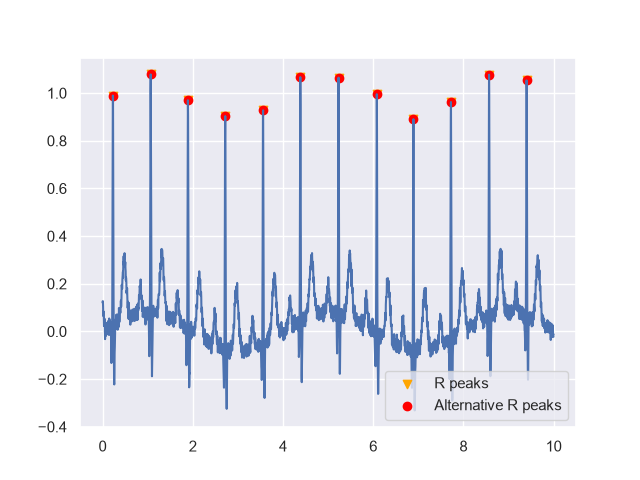

In [8]:
alt_r_peaks = percentile_find_peaks(ecg_data, percentile=99, distance=MIN_PEAK_DISTANCE)

# Plot the ECG data with the alternative R peaks marked
plt.figure()
sns.lineplot(x=time_axis, y=ecg_data)
plt.scatter(
    time_axis[r_peaks], ecg_data[r_peaks],
    label='R peaks', color='orange', marker='v')
plt.scatter(
    time_axis[alt_r_peaks], ecg_data[alt_r_peaks],
    label='Alternative R peaks', color='red', marker='o')
# put legend southeast of the plot
plt.legend(loc='lower right')
plt.show()

To further improve, the percentile threshold can be determined with a sliding window in a second pass after determining a rough heart rate from the first pass. This makes the threshold more adaptive to the local signal characteristics, which can be useful when the ECG signal has varying amplitude due to noise or other factors.

That said, finding a local maximum (which is what `scipy.signal.find_peaks` does) is usually a more robust approach than using a fixed threshold, especially when the signal has varying amplitude or noise. However it still requires some parameter tuning (like `height`, `distance`, etc.) to get the best results for a specific dataset. So combining both (adaptive thresholding and peak finding) can be a good strategy to improve the accuracy of R peak detection in ECG signals.

There are certainly more accurate methods for ECG R peak detection, such as the Pan-Tompkins algorithm [1], which is a widely used method for real-time QRS detection. It involves several steps including bandpass filtering, differentiation, squaring, and moving window integration to enhance the QRS complex and suppress noise. However, implementing such algorithms can be more complex and may require additional signal processing knowledge.

[1]: Pan J, Tompkins W J. A real-time QRS detection algorithm[J]. IEEE transactions on biomedical engineering, 1985 (3): 230-236.

## Calculate heart beats, heart rate, and RR intervals

In [9]:
heart_beats = len(alt_r_peaks)
rr_intervals = np.diff(alt_r_peaks) / SAMPLE_RATE  # in seconds
# pad with NaN for the first interval
rr_intervals = np.pad(rr_intervals, (1, 0), 'constant', constant_values=np.nan)
heart_rate_by_beat = 60 / rr_intervals  # in bpm
# peak-to-peak overall heart rate, period from the first to the last detected R peak
heart_rate_overall = 60 * (heart_beats - 1) / ((alt_r_peaks[-1] - alt_r_peaks[0]) / SAMPLE_RATE)
# heart rate variability (HRV) can be calculated as the standard deviation of the RR intervals
hrv = np.std(rr_intervals[1:])  # exclude the first NaN value

print(f"Number of heart beats detected: {heart_beats}")
print(f"RR intervals (s): {rr_intervals}")
print(f"Heart rate by beat (bpm): {heart_rate_by_beat}")
print(f"Overall heart rate (bpm): {heart_rate_overall:.2f}")
print(f"Heart rate variability (HRV): {hrv:.4f} s, or {60 * hrv:.2f} bpm")

Number of heart beats detected: 12
RR intervals (s): [  nan 0.84  0.824 0.828 0.84  0.824 0.848 0.848 0.812 0.832 0.844 0.832]
Heart rate by beat (bpm): [        nan 71.42857143 72.81553398 72.46376812 71.42857143 72.81553398
 70.75471698 70.75471698 73.89162562 72.11538462 71.09004739 72.11538462]
Overall heart rate (bpm): 71.96
Heart rate variability (HRV): 0.0108 s, or 0.65 bpm


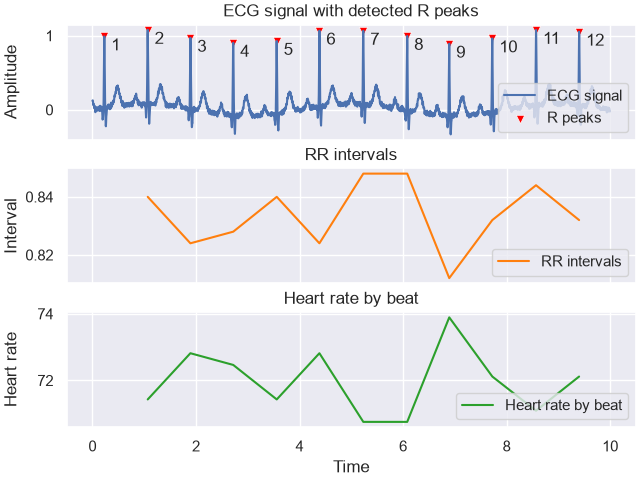

In [10]:
fig, axes = plt.subplots(nrows=3,ncols=1,sharex=True,constrained_layout=True)

# 1. ECG signal and R peaks
sns.lineplot(
    x=time_axis,y=ecg_data,
    ax=axes[0],label="ECG signal")

sns.scatterplot(
    x=time_axis[alt_r_peaks],y=ecg_data[alt_r_peaks],
    ax=axes[0],label="R peaks",color="red",marker="v")

for beat, peak in enumerate(alt_r_peaks, start=1):
    axes[0].annotate(
        str(beat),
        (time_axis[peak], ecg_data[peak]),
        xytext=(5, -10),
        textcoords="offset points",
        ha="left"
    )

axes[0].set_title("ECG signal with detected R peaks")
axes[0].set_ylabel("Amplitude")
axes[0].legend(loc="lower right")

# 2. RR intervals
sns.lineplot(
    x=time_axis[alt_r_peaks],y=rr_intervals,
    ax=axes[1],label="RR intervals",color="tab:orange")

axes[1].set_title("RR intervals")
axes[1].set_ylabel("Interval")
axes[1].legend(loc="lower right")

# 3. Heart rate by beat
sns.lineplot(
    x=time_axis[alt_r_peaks],y=heart_rate_by_beat,
    ax=axes[2],label="Heart rate by beat",color="tab:green")

axes[2].set_title("Heart rate by beat")
axes[2].set_xlabel("Time")
axes[2].set_ylabel("Heart rate")
axes[2].legend(loc="lower right")

# Align subplot labels and justify the layout
fig.align_ylabels(axes)
plt.show()

## Results and Discussion

Calculated results:
```
Number of heart beats detected: 12
RR intervals (s): [  nan 0.84  0.824 0.828 0.84  0.824 0.848 0.848 0.812 0.832 0.844 0.832]
Heart rate by beat (bpm): [        nan 71.42857143 72.81553398 72.46376812 71.42857143 72.81553398
 70.75471698 70.75471698 73.89162562 72.11538462 71.09004739 72.11538462]
Overall heart rate (bpm): 71.96
Heart rate variability (HRV): 0.0108 s, or 0.65 bpm
```

Indicating a successful detection of the R peaks and calculation of the heart rate and RR intervals. The overall heart rate is within the normal range for adults (60~90 bpm), and the HRV indicates a relatively stable heart rhythm.

Summary of implementation:
- Load ECG data from a text file.
- Identify R peaks using both `scipy.signal.find_peaks` and an alternative method based on boolean indexing and statistics.
- Calculate RR intervals and heart rate by beat.

Improvements can be made at the pre-processing stage. For example, applying a bandpass filter to the ECG signal can help reduce power line interference (for example at 50 Hz or 60 Hz), respiratory noise (usually below 0.5 Hz), and high-frequency noise (usually above 40 Hz). This can make the signal cleaner and improve the accuracy of R peak detection. Additionally, using more advanced algorithms like the Pan-Tompkins algorithm can further enhance the detection accuracy.

For example, with a higher level of noise (adding gaussian noise to the signal):

FloatSlider(value=0.42, description='Noise Level:', max=2.0, step=0.01)

Output()

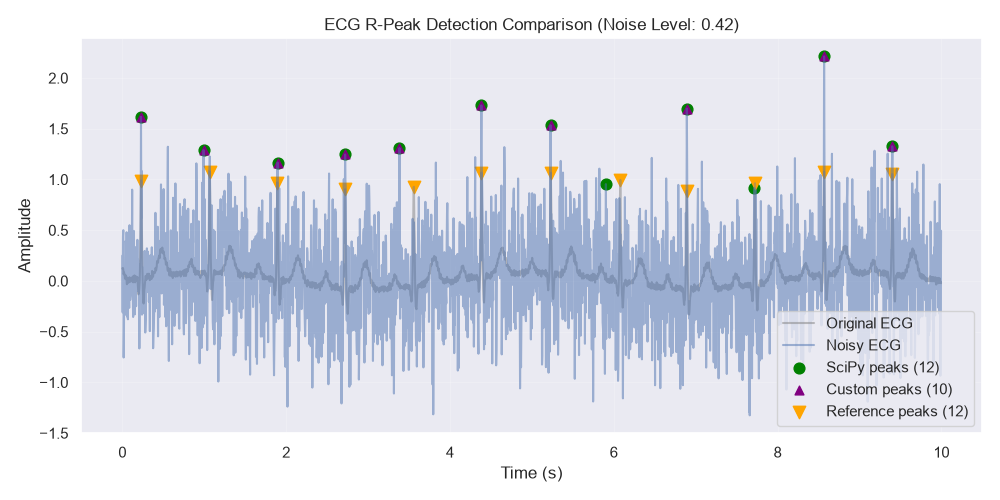

In [11]:
# simulate higher level of noise in the ECG signal by adding Gaussian noise
# using a slider in notebook for interactive visualization

from IPython.display import display
DEFAULT_NOISE_LEVEL = 0.42

rng = np.random.default_rng(42)
unit_noise = rng.normal(0, 1, len(ecg_data))


fig1, ax1 = plt.subplots(figsize=(10, 5))


def plot_comparison(noise_level):
    noisy_ecg = ecg_data + noise_level * unit_noise

    scipy_peaks, _ = signal.find_peaks(
        noisy_ecg, height=0.5, distance=MIN_PEAK_DISTANCE
    )
    custom_peaks = percentile_find_peaks(
        noisy_ecg, percentile=95.45, distance=MIN_PEAK_DISTANCE
    )

    ax1.clear()
    ax1.plot(time_axis, ecg_data, label='Original ECG',
            color='gray', alpha=0.5)
    ax1.plot(time_axis, noisy_ecg, label='Noisy ECG', alpha=0.5)
    ax1.scatter(time_axis[scipy_peaks], noisy_ecg[scipy_peaks],
               label=f'SciPy peaks ({len(scipy_peaks)})',
               color='green', s=60)
    ax1.scatter(time_axis[custom_peaks], noisy_ecg[custom_peaks],
               label=f'Custom peaks ({len(custom_peaks)})',
               color='purple', marker='^', s=40)
    ax1.scatter(time_axis[alt_r_peaks], ecg_data[alt_r_peaks],
               label=f'Reference peaks ({len(alt_r_peaks)})',
               color='orange', marker='v', s=80)

    ax1.set_title(f'ECG R-Peak Detection Comparison '
                 f'(Noise Level: {noise_level:.2f})')
    ax1.set_xlabel('Time (s)')
    ax1.set_ylabel('Amplitude')
    ax1.legend(loc="lower right")
    ax1.grid(alpha=0.2)
    fig1.tight_layout()



import ipywidgets as widgets

noise_slider_1 = widgets.FloatSlider(
    value=DEFAULT_NOISE_LEVEL,
    min=0.0,
    max=2,
    step=0.01,
    description='Noise Level:',
    continuous_update=True
)

out = widgets.interactive_output(
    plot_comparison, {'noise_level': noise_slider_1}
)

display(noise_slider_1, out)

By moving the slider from 0 to 2 we can see that generally the number of peaks that the scipy algorithm is almost constant even under heavy noise, which is very robust to noise. Our custom algorithm can also be tuned to be more robust to noise by adjusting the percentile threshold, while it is still more sensitive to noise and may miss more peaks under heavy noise.

The most impacted part is the lower peaks. Applying a 0.5-40 Hz bandpass filter at the preprocessing stage:

FloatSlider(value=0.42, description='Noise Level:', max=2.0, step=0.01)

Output()

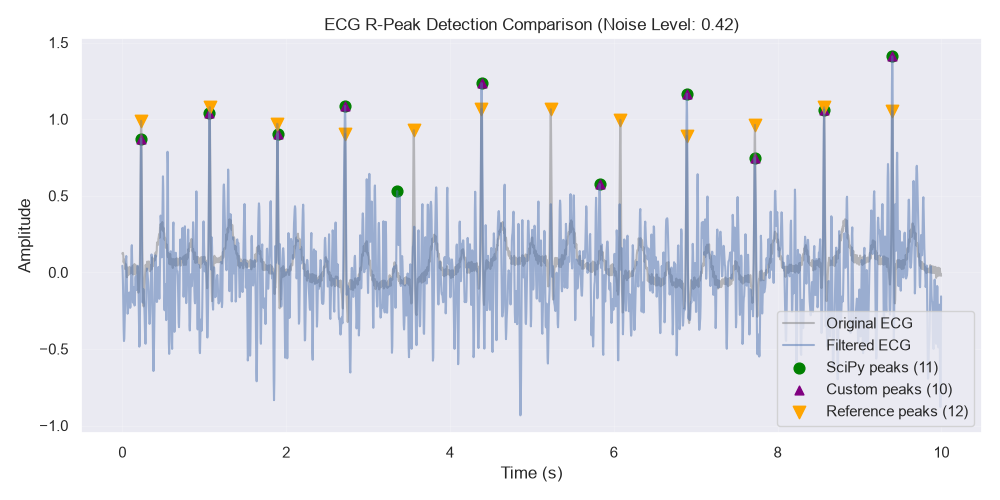

In [12]:
fig2, ax2 = plt.subplots(figsize=(10, 5))


def plot_comparison_with_lpf(noise_level):
    noisy_ecg = ecg_data + noise_level * unit_noise

    # 0.5-40 Hz BPF
    sos = signal.butter(
        4,
        [0.5, 40],
        btype='bandpass',
        fs=SAMPLE_RATE,
        output='sos'
    )
    filtered_ecg = signal.sosfiltfilt(sos, noisy_ecg)

    scipy_peaks, _ = signal.find_peaks(
        filtered_ecg, height=0.5, distance=MIN_PEAK_DISTANCE
    )
    custom_peaks = percentile_find_peaks(
        filtered_ecg, percentile=95.45, distance=MIN_PEAK_DISTANCE
    )

    ax2.clear()
    ax2.plot(time_axis, ecg_data, label='Original ECG',
            color='gray', alpha=0.5)
    ax2.plot(time_axis, filtered_ecg, label='Filtered ECG', alpha=0.5)
    ax2.scatter(time_axis[scipy_peaks], filtered_ecg[scipy_peaks],
               label=f'SciPy peaks ({len(scipy_peaks)})',
               color='green', s=60)
    ax2.scatter(time_axis[custom_peaks], filtered_ecg[custom_peaks],
               label=f'Custom peaks ({len(custom_peaks)})',
               color='purple', marker='^', s=40)
    ax2.scatter(time_axis[alt_r_peaks], ecg_data[alt_r_peaks],
               label=f'Reference peaks ({len(alt_r_peaks)})',
               color='orange', marker='v', s=80)

    ax2.set_title(f'ECG R-Peak Detection Comparison '
                 f'(Noise Level: {noise_level:.2f})')
    ax2.set_xlabel('Time (s)')
    ax2.set_ylabel('Amplitude')
    ax2.legend(loc="lower right")
    ax2.grid(alpha=0.2)
    fig2.tight_layout()

noise_slider_2 = widgets.FloatSlider(
    value=DEFAULT_NOISE_LEVEL,
    min=0.0,
    max=2,
    step=0.01,
    description='Noise Level:',
    continuous_update=True
)
out = widgets.interactive_output(
    plot_comparison_with_lpf, {'noise_level': noise_slider_2}
)

display(noise_slider_2, out)

Applying this BPF enhances the signal quality when the noise level is lower. However if the noise level comes to the same order of magnitude as the signal, the BPF may not be able to recover the signal quality. In this case, more advanced denoising techniques may be needed, such as wavelet denoising or adaptive filtering.

To conclude, the R peak detection is successful and the heart rate and RR intervals are calculated accurately with the given ECG data. Further improvements can be made by applying appropriate filtering techniques and using more advanced algorithms for R peak detection.